# Автоматическое определение характеристик вина по описанию

Цель — построить воспроизводимый ML-пайплайн, который по русскоязычному описанию вина определяет:

- категориальные признаки: `acidity_level`, `tannin_level`, `body_level`, `intensity_level`;
- мультиметочные признаки: `aroma_notes`, `taste_notes`.

Ноутбук включает аудит данных, EDA, подготовку текста и меток, обучение TF–IDF-моделей, оценку, анализ ошибок, сохранение артефактов и пример инференса.

> **Важное ограничение текущего файла.** В `data/wines.csv` сейчас 42 объекта (а не около 3 000), все шесть целевых полей пусты, а интенсивность названа `taste_intensity`. Поэтому ноутбук автоматически включает **демонстрационный режим слабой разметки**. Такие метки извлекаются из текста правилами и не являются заменой ручной разметки; метрики в этом режиме показывают воспроизводимость правил, а не реальную обобщающую способность модели. Если заменить CSV на размеченный, код автоматически перейдёт в обычный supervised-режим.

In [1]:
from pathlib import Path
import ast
import json
import re
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, f1_score, hamming_loss,
    multilabel_confusion_matrix
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Работает и при запуске из корня проекта, и из папки notebooks.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "wines.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "wines.csv"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
ARTIFACTS_DIR.mkdir(exist_ok=True)

print("Датасет:", DATA_PATH.resolve())
print("Артефакты:", ARTIFACTS_DIR.resolve())

/Users/sergej/venvs/ds-ml-py311/lib/python3.11/site-packages/seaborn/_statistics.py:32: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.4.6)
  from scipy.stats import gaussian_kde


Датасет: /Users/sergej/Desktop/УрФУ/Семестр 3/Интеграции ИИ в разработку/project/data/wines.csv
Артефакты: /Users/sergej/Desktop/УрФУ/Семестр 3/Интеграции ИИ в разработку/project/artifacts


## 1. Загрузка и аудит качества данных

Сначала проверим размер, схему, пропуски, дубликаты и наличие разметки. Это особенно важно: модель с учителем нельзя честно обучить без заполненных целевых переменных.

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Размер: {df.shape[0]} строк × {df.shape[1]} столбцов")
display(df.head(3))

required_features = ["description"]
categorical_targets = ["acidity_level", "tannin_level", "body_level", "intensity_level"]
multilabel_targets = ["aroma_notes", "taste_notes"]

# В исходной схеме интенсивность называется taste_intensity.
if "intensity_level" not in df.columns and "taste_intensity" in df.columns:
    df["intensity_level"] = df["taste_intensity"]

missing_columns = [c for c in required_features + categorical_targets + multilabel_targets if c not in df]
if missing_columns:
    raise ValueError(f"В CSV отсутствуют обязательные столбцы: {missing_columns}")

audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "unique": df.nunique(dropna=True),
}).sort_values("missing_%", ascending=False)
display(audit.loc[list(dict.fromkeys(required_features + categorical_targets + multilabel_targets))])

print("Полные дубликаты:", int(df.duplicated().sum()))
if "id" in df:
    print("Дубликаты id:", int(df["id"].duplicated().sum()))

Размер: 42 строк × 50 столбцов


,id,source,product_code,name,brand,category,producer,country,region,classification,...,taste_intensity,alcohol_perception,wine_style,is_active,is_full_info,is_additional_features,error,is_approve,created_at,updated_at
0,1,winelab,1000217,Вино Torres San Valentin Garnacha красное сухо...,Torres,Вина с защищенным наименованием | Каталония,Torres,Испания,Каталония,Вина с защищенным наименованием,...,NaN,NaN,NaN,False,True,False,"{""category"": {""first_load"": ""Вина с защищенным...",False,2026-10-22T13:23:11,2026-10-22T13:23:26
1,2,winelab,1007629,Вино Zonin 20 Ventiterre Pinot Grigio белое су...,ZONIN,Вина с защищенным наименованием | Сицилия,ZONIN,Италия,Сицилия,Вина с защищенным наименованием,...,NaN,NaN,NaN,False,True,False,"{""category"": {""first_load"": ""Вина с защищенным...",False,2026-10-22T13:23:11,2026-10-22T13:23:27
2,3,winelab,1016145,"Вино Calvet Cahors Malbec красное сухое 0,75 л",Calvet,Вина с защищенным наименованием | Юго-Запад,Les Grands Chais de France,Франция,Юго-Запад,Вина с защищенным наименованием,...,NaN,NaN,NaN,False,True,False,"{""category"": {""first_load"": ""Вина с защищенным...",False,2026-10-22T13:23:11,2026-10-22T13:23:29


,dtype,missing,missing_%,unique
description,str,17,40.5,25
acidity_level,float64,42,100.0,0
tannin_level,float64,42,100.0,0
body_level,float64,42,100.0,0
intensity_level,float64,42,100.0,0
aroma_notes,float64,42,100.0,0
taste_notes,float64,42,100.0,0


Полные дубликаты: 0
Дубликаты id: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country,42,14,Италия,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
color,40,3,Белое,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sweetness,41,4,Сухое,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,42.0,NaN,NaN,NaN,4.524047,0.275419,3.809677,4.391667,4.6,4.7,5.0
price,42.0,NaN,NaN,NaN,955.417143,395.867191,379.99,599.99,924.99,1199.99,1998.99


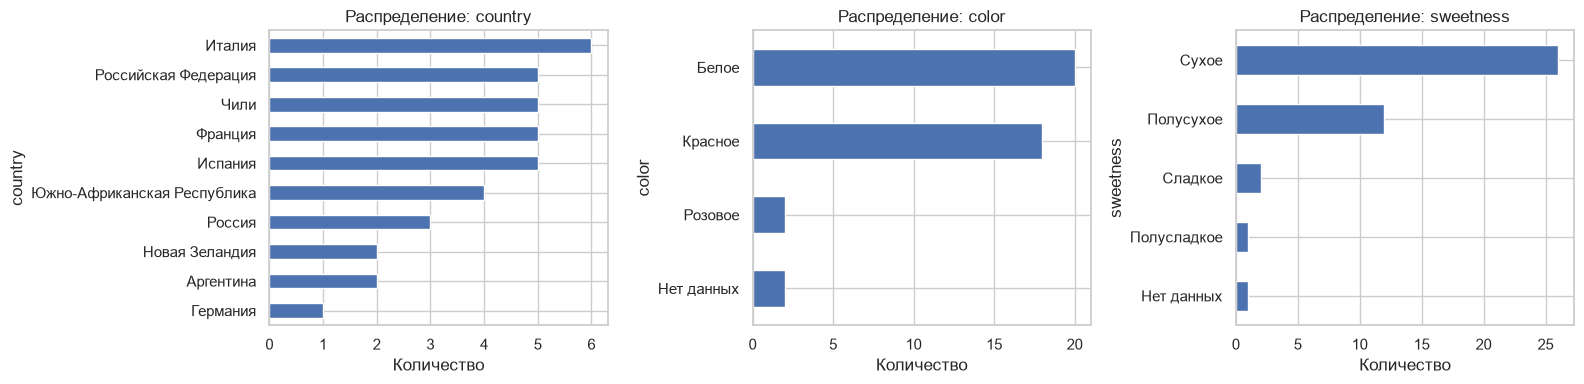

In [3]:
# Короткий EDA по доступным бизнес-признакам.
eda_columns = [c for c in ["country", "color", "sweetness", "rating", "price"] if c in df]
display(df[eda_columns].describe(include="all").T)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, column in zip(axes, ["country", "color", "sweetness"]):
    if column in df:
        df[column].fillna("Нет данных").value_counts().head(10).sort_values().plot.barh(ax=ax)
        ax.set_title(f"Распределение: {column}")
        ax.set_xlabel("Количество")
plt.tight_layout()
plt.show()

## 2. Подготовка текста и целевых переменных

Для текста объединяем название, основное описание и рекомендацию по употреблению. Производственные и брендовые истории намеренно не добавляются: они длинные и обычно не описывают органолептику конкретного вина.

Для настоящей разметки поддерживаются JSON-списки (`["цитрус", "минералы"]`), Python-подобные списки и строки с разделителями `,`, `;`, `|`. Категории приводятся к нижнему регистру.

In [4]:
text_columns = [c for c in ["name", "description", "consumption_recommendation"] if c in df]

def clean_text(value):
    value = "" if pd.isna(value) else str(value)
    value = value.lower().replace("ё", "е")
    value = re.sub(r"https?://\S+|www\.\S+", " ", value)
    value = re.sub(r"\s+", " ", value)
    return value.strip()

df["model_text"] = (
    df[text_columns].fillna("").astype(str).agg(" ".join, axis=1).map(clean_text)
)
df = df[df["model_text"].str.len() >= 10].drop_duplicates("model_text").reset_index(drop=True)

def parse_labels(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return []
    if isinstance(value, (list, tuple, set)):
        values = list(value)
    else:
        raw = str(value).strip()
        if not raw:
            return []
        try:
            parsed = json.loads(raw)
        except (json.JSONDecodeError, TypeError):
            try:
                parsed = ast.literal_eval(raw)
            except (ValueError, SyntaxError):
                parsed = re.split(r"[,;|]", raw)
        values = parsed if isinstance(parsed, (list, tuple, set)) else [parsed]
    return sorted({clean_text(x) for x in values if clean_text(x)})

for column in categorical_targets:
    df[column] = df[column].map(lambda x: np.nan if pd.isna(x) or not str(x).strip() else clean_text(x))
for column in multilabel_targets:
    df[column] = df[column].map(parse_labels)

label_audit = pd.DataFrame({
    "non_empty": [
        int(df[c].notna().sum()) if c in categorical_targets else int(df[c].map(bool).sum())
        for c in categorical_targets + multilabel_targets
    ],
    "unique_or_labels": [
        int(df[c].nunique(dropna=True)) if c in categorical_targets
        else len({x for values in df[c] for x in values})
        for c in categorical_targets + multilabel_targets
    ],
}, index=categorical_targets + multilabel_targets)
display(label_audit)

,non_empty,unique_or_labels
acidity_level,0,0
tannin_level,0,0
body_level,0,0
intensity_level,0,0
aroma_notes,0,0
taste_notes,0,0


### Демонстрационная слабая разметка

Режим включается только если настоящих меток недостаточно. Словари извлекают явные упоминания из описания; категориальные правила используют органолептические маркеры и цвет вина. Это делает проект исполняемым на текущем CSV, но создаёт **утечку цели из текста**: именно поэтому итоговые demo-метрики нельзя использовать как оценку production-модели.

In [5]:
enough_real_labels = (
    len(df) >= 30
    and all(df[c].notna().sum() >= 30 and df[c].nunique(dropna=True) >= 2 for c in categorical_targets)
    and all(df[c].map(bool).sum() >= 30 for c in multilabel_targets)
)
DEMO_WEAK_LABELS = not enough_real_labels

NOTE_LEXICON = {
    "красные ягоды": ["красн.*ягод", "вишн", "клубник", "малин", "земляник", "брусник", "клюкв"],
    "черные ягоды": ["черн.*ягод", "смородин", "ежевик", "черник"],
    "цитрусы": ["цитрус", "лимон", "лайм", "грейпфрут", "апельсин", "мандарин"],
    "тропические фрукты": ["тропичес", "ананас", "манго", "маракуй", "банан"],
    "косточковые фрукты": ["косточков", "персик", "абрикос", "слив", "нектарин"],
    "яблоко и груша": ["яблок", "груш"],
    "цветы": ["цветоч", "цветущ", "жасмин", "фиалк", "роза", "боярышник"],
    "пряности": ["пряност", "специ", "перец", "кориц", "гвоздик"],
    "древесина": ["древес", "дуб", "кедр", "бочк"],
    "минералы": ["минерал", "кремни", "мел", "слан"],
    "сухофрукты": ["сухофрукт", "чернослив", "изюм", "кураг"],
    "ваниль": ["ванил"],
    "шоколад": ["шоколад", "какао"],
    "табак": ["табак"],
    "травы": ["трав", "папорот", "эвкалипт", "мят"],
    "мед": ["медов", "\bмед\b"],
}

def extract_section(text, section):
    # Описания поставщика часто имеют секции «Аромат:» и «Вкус:».
    match = re.search(rf"{section}\s*:\s*(.*?)(?=\s(?:цвет|аромат|вкус)\s*:|$)", text, flags=re.I | re.S)
    return match.group(1) if match else text

def extract_notes(text):
    return sorted([
        label for label, patterns in NOTE_LEXICON.items()
        if any(re.search(pattern, text, flags=re.I) for pattern in patterns)
    ])

def weak_acidity(text, color):
    if re.search(r"хрустящ.*кисл|ярк.*кисл|высок.*кисл|свеж.*кисл", text): return "высокая"
    if re.search(r"мягк.*кисл|низк.*кисл", text): return "низкая"
    return "высокая" if color in {"белое", "розовое"} else "средняя"

def weak_tannin(text, color):
    if re.search(r"мощн.*танин|выраженн.*танин|терпк", text): return "высокая"
    if re.search(r"мягк.*танин|шелковист.*танин|округл.*танин", text): return "средняя"
    return "средняя" if color == "красное" else "низкая"

def weak_body(text):
    if re.search(r"плотн|насыщенн|богат|полнотел|мощн", text): return "полное"
    if re.search(r"легк|воздуш|невесом", text): return "легкое"
    return "среднее"

def weak_intensity(text):
    if re.search(r"интенсив|ярк|выразитель|насыщенн|богат", text): return "высокая"
    if re.search(r"деликат|нежн|тонк|легк", text): return "низкая"
    return "средняя"

if DEMO_WEAK_LABELS:
    color_series = df.get("color", pd.Series("", index=df.index)).fillna("").map(clean_text)
    df["acidity_level"] = [weak_acidity(t, c) for t, c in zip(df["model_text"], color_series)]
    df["tannin_level"] = [weak_tannin(t, c) for t, c in zip(df["model_text"], color_series)]
    df["body_level"] = df["model_text"].map(weak_body)
    df["intensity_level"] = df["model_text"].map(weak_intensity)
    df["aroma_notes"] = df["model_text"].map(lambda t: extract_notes(extract_section(t, "аромат")))
    df["taste_notes"] = df["model_text"].map(lambda t: extract_notes(extract_section(t, "вкус")))

    # Пустой набор — допустимая мультиметка. Для обучения оставим только достаточно частые классы.
    print("⚠ Включен DEMO-режим слабой разметки. Метрики не являются production-оценкой.")
else:
    # В supervised-режиме строки с незаполненными целями не участвуют в обучении.
    complete_mask = df[categorical_targets].notna().all(axis=1)
    complete_mask &= df[multilabel_targets].map(bool).all(axis=1)
    dropped = int((~complete_mask).sum())
    df = df.loc[complete_mask].reset_index(drop=True)
    print("Используется настоящая разметка из CSV.")
    print("Исключено строк с незаполненными целями:", dropped)

print("Объектов после очистки:", len(df))
display(df[["model_text"] + categorical_targets + multilabel_targets].head(5))

⚠ Включен DEMO-режим слабой разметки. Метрики не являются production-оценкой.
Объектов после очистки: 42


,model_text,acidity_level,tannin_level,body_level,intensity_level,aroma_notes,taste_notes
0,вино torres san valentin garnacha красное сухо...,средняя,средняя,полное,высокая,"[пряности, черные ягоды]",[пряности]
1,вино zonin 20 ventiterre pinot grigio белое су...,высокая,низкая,среднее,низкая,"[косточковые фрукты, минералы]",[минералы]
2,"вино calvet cahors malbec красное сухое 0,75 л...",средняя,средняя,полное,высокая,"[красные ягоды, травы, черные ягоды]",[]
3,"вино uvc petit chablis белое сухое 0,75 л фран...",высокая,высокая,полное,высокая,"[минералы, цветы, цитрусы]","[минералы, травы, цитрусы]"
4,вино il gaggio montepulciano d’abruzzo о красн...,высокая,высокая,среднее,высокая,"[древесина, красные ягоды, пряности, черные яг...","[косточковые фрукты, сухофрукты]"


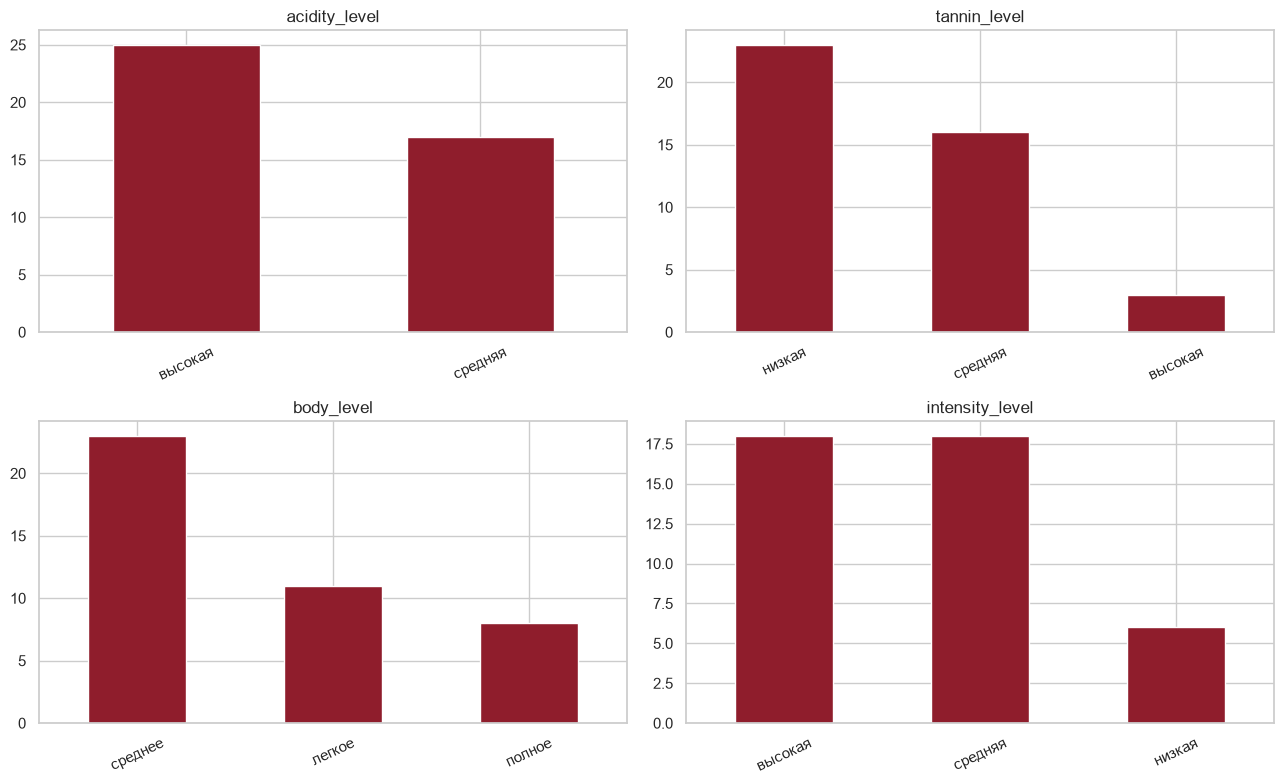

aroma_notes: 12 уникальных нот; в среднем 1.14 метки/объект


,count
черные ягоды,7
красные ягоды,7
цитрусы,7
пряности,6
цветы,4
яблоко и груша,4
минералы,3
травы,3
косточковые фрукты,2
древесина,2


taste_notes: 9 уникальных нот; в среднем 0.57 метки/объект


,count
цитрусы,6
минералы,4
пряности,2
травы,2
косточковые фрукты,2
сухофрукты,2
цветы,2
тропические фрукты,2
яблоко и груша,2


In [6]:
# Распределение целевых категорий и частых нот.
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, target in zip(axes.ravel(), categorical_targets):
    df[target].value_counts().plot.bar(ax=ax, color="#8f1d2c")
    ax.set_title(target)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

for target in multilabel_targets:
    counts = pd.Series([label for labels in df[target] for label in labels]).value_counts()
    print(f"{target}: {len(counts)} уникальных нот; в среднем {df[target].map(len).mean():.2f} метки/объект")
    display(counts.rename("count").to_frame().head(15))

## 3. Разделение данных и TF–IDF

Используется единый hold-out 75/25, чтобы все модели оценивались на одних объектах. TF–IDF обучается **только на train**, что исключает утечку словаря из теста. Символьные n-граммы хорошо работают с русской морфологией, опечатками и небольшими данными без внешних языковых моделей.

In [7]:
if len(df) < 20:
    raise ValueError("После очистки осталось менее 20 объектов: для ML-демонстрации этого недостаточно.")

indices = np.arange(len(df))
train_idx, test_idx = train_test_split(indices, test_size=0.25, random_state=RANDOM_STATE)
X_train_text = df.loc[train_idx, "model_text"]
X_test_text = df.loc[test_idx, "model_text"]

vectorizer = TfidfVectorizer(
    analyzer="char_wb", ngram_range=(3, 5), min_df=1,
    max_features=30_000, sublinear_tf=True
)
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

print("Train/test:", X_train.shape[0], "/", X_test.shape[0])
print("TF–IDF-признаков:", X_train.shape[1])

Train/test: 31 / 11
TF–IDF-признаков: 8610


## 4. Категориальная классификация

Для каждой характеристики обучается отдельная логистическая регрессия с балансировкой классов. Если в маленькой train-выборке случайно остался один класс, используется честный `DummyClassifier`, чтобы пайплайн не падал.

In [8]:
categorical_models = {}
categorical_rows = []
categorical_predictions = {}

for target in categorical_targets:
    y_train = df.loc[train_idx, target].astype(str)
    y_test = df.loc[test_idx, target].astype(str)
    if y_train.nunique() < 2:
        model = DummyClassifier(strategy="most_frequent")
    else:
        model = LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    categorical_models[target] = model
    categorical_predictions[target] = pred
    categorical_rows.append({
        "target": target,
        "accuracy": accuracy_score(y_test, pred),
        "macro_f1": f1_score(y_test, pred, average="macro", zero_division=0),
        "train_classes": y_train.nunique(),
    })

categorical_metrics = pd.DataFrame(categorical_rows).set_index("target")
display(categorical_metrics.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}"}))

for target in categorical_targets:
    print("\n", target)
    print(classification_report(
        df.loc[test_idx, target].astype(str), categorical_predictions[target], zero_division=0
    ))

,accuracy,macro_f1,train_classes
target,,,
acidity_level,0.636,0.607,2
tannin_level,0.909,0.630,3
body_level,0.545,0.524,3
intensity_level,0.818,0.625,3



 acidity_level
              precision    recall  f1-score   support

     высокая       0.71      0.71      0.71         7
     средняя       0.50      0.50      0.50         4

    accuracy                           0.64        11
   macro avg       0.61      0.61      0.61        11
weighted avg       0.64      0.64      0.64        11


 tannin_level
              precision    recall  f1-score   support

     высокая       0.00      0.00      0.00         1
      низкая       1.00      1.00      1.00         6
     средняя       0.80      1.00      0.89         4

    accuracy                           0.91        11
   macro avg       0.60      0.67      0.63        11
weighted avg       0.84      0.91      0.87        11


 body_level
              precision    recall  f1-score   support

      легкое       0.43      1.00      0.60         3
      полное       0.50      0.33      0.40         3
     среднее       1.00      0.40      0.57         5

    accuracy                  

## 5. Мультиметочная классификация нот

Каждая нота — отдельная бинарная задача. Редкие ноты с менее чем двумя положительными примерами исключаются из моделирования: их невозможно надёжно разделить между train и test. Порог вероятности `0.35` повышает полноту по сравнению со стандартным `0.5`; для production его следует подобрать на отдельной validation-выборке.

In [9]:
def fit_multilabel(target, threshold=0.35):
    all_labels = pd.Series([x for values in df[target] for x in values]).value_counts()
    eligible = all_labels[(all_labels >= 2) & (all_labels <= len(df) - 2)].index.tolist()
    if not eligible:
        raise ValueError(f"Для {target} нет нот минимум с 2 наблюдениями")

    mlb = MultiLabelBinarizer(classes=eligible)
    Y = mlb.fit_transform(df[target].map(lambda xs: [x for x in xs if x in eligible]))
    Y_train, Y_test = Y[train_idx], Y[test_idx]
    models, probs = {}, np.zeros_like(Y_test, dtype=float)

    for j, label in enumerate(mlb.classes_):
        if np.unique(Y_train[:, j]).size < 2:
            clf = DummyClassifier(strategy="most_frequent")
        else:
            clf = LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE)
        clf.fit(X_train, Y_train[:, j])
        models[label] = clf
        if hasattr(clf, "predict_proba"):
            classes = list(clf.classes_)
            probs[:, j] = clf.predict_proba(X_test)[:, classes.index(1)] if 1 in classes else 0.0
        else:
            probs[:, j] = clf.predict(X_test)

    pred = (probs >= threshold).astype(int)
    metrics = {
        "labels": len(eligible),
        "micro_f1": f1_score(Y_test, pred, average="micro", zero_division=0),
        "macro_f1": f1_score(Y_test, pred, average="macro", zero_division=0),
        "samples_f1": f1_score(Y_test, pred, average="samples", zero_division=0),
        "hamming_loss": hamming_loss(Y_test, pred),
        "exact_match": accuracy_score(Y_test, pred),
    }
    return {"mlb": mlb, "models": models, "threshold": threshold}, Y_test, pred, metrics

multilabel_models = {}
multilabel_outputs = {}
multilabel_rows = []

for target in multilabel_targets:
    bundle, y_true, y_pred, metrics = fit_multilabel(target)
    multilabel_models[target] = bundle
    multilabel_outputs[target] = (y_true, y_pred)
    multilabel_rows.append({"target": target, **metrics})

multilabel_metrics = pd.DataFrame(multilabel_rows).set_index("target")
display(multilabel_metrics.style.format({
    "micro_f1": "{:.3f}", "macro_f1": "{:.3f}", "samples_f1": "{:.3f}",
    "hamming_loss": "{:.3f}", "exact_match": "{:.3f}"
}))

,labels,micro_f1,macro_f1,samples_f1,hamming_loss,exact_match
target,,,,,,
aroma_notes,11,0.279,0.198,0.218,0.512,0.182
taste_notes,9,0.258,0.091,0.177,0.232,0.273


## 6. Анализ ошибок

Таблица ниже сопоставляет текст, истинные и предсказанные значения. В настоящем supervised-режиме она помогает найти неоднозначные описания, ошибки разметки, редкие классы и систематические промахи модели.

In [10]:
error_table = df.loc[test_idx, ["name", "model_text"]].copy() if "name" in df else df.loc[test_idx, ["model_text"]].copy()
error_table = error_table.reset_index(drop=True)
for target in categorical_targets:
    error_table[f"{target}_true"] = df.loc[test_idx, target].astype(str).to_numpy()
    error_table[f"{target}_pred"] = categorical_predictions[target]
for target in multilabel_targets:
    y_true, y_pred = multilabel_outputs[target]
    mlb = multilabel_models[target]["mlb"]
    error_table[f"{target}_true"] = list(mlb.inverse_transform(y_true))
    error_table[f"{target}_pred"] = list(mlb.inverse_transform(y_pred))

display(error_table.head(10))
error_table.to_csv(ARTIFACTS_DIR / "test_predictions.csv", index=False)

,name,model_text,acidity_level_true,acidity_level_pred,tannin_level_true,tannin_level_pred,body_level_true,body_level_pred,intensity_level_true,intensity_level_pred,aroma_notes_true,aroma_notes_pred,taste_notes_true,taste_notes_pred
0,"Вино Levitation Sauvignon Blanc белое сухое 0,...","вино levitation sauvignon blanc белое сухое 0,...",высокая,высокая,низкая,низкая,полное,легкое,высокая,высокая,"(цитрусы,)","(черные ягоды, красные ягоды, цитрусы, пряност...","(цитрусы, тропические фрукты)","(минералы,)"
1,Вино The Grill Master Fan Club Malbec красное ...,вино the grill master fan club malbec красное ...,средняя,средняя,средняя,средняя,среднее,среднее,средняя,средняя,(),(),(),()
2,Вино Golubitskoe Estate Red Blend Cabernet Sau...,вино golubitskoe estate red blend cabernet sau...,средняя,высокая,средняя,средняя,среднее,легкое,высокая,высокая,(),"(черные ягоды, красные ягоды, цитрусы, пряност...",(),"(минералы, пряности)"
3,Вермут Martini Fiero сладкий 1 л,вермут martini fiero сладкий 1 л вермут раскры...,средняя,высокая,низкая,низкая,среднее,легкое,высокая,высокая,"(цитрусы,)","(черные ягоды, красные ягоды, цитрусы, пряност...","(цитрусы,)","(цитрусы, минералы)"
4,Вино Il Gaggio Montepulciano d’Abruzzo о красн...,вино il gaggio montepulciano d’abruzzo о красн...,высокая,средняя,высокая,средняя,среднее,полное,высокая,высокая,"(черные ягоды, красные ягоды, пряности, древес...","(черные ягоды, красные ягоды, цитрусы, пряност...","(косточковые фрукты, сухофрукты)","(цитрусы, минералы, пряности)"
5,Вино Cono Sur Bicicleta Pinot Grigio белое пол...,вино cono sur bicicleta pinot grigio белое пол...,высокая,высокая,низкая,низкая,легкое,легкое,высокая,высокая,"(цитрусы, яблоко и груша)","(черные ягоды, красные ягоды, цитрусы, пряност...","(цитрусы, яблоко и груша)","(цитрусы, минералы)"
6,Вино Torres San Valentin Sauvignon Blanc белое...,вино torres san valentin sauvignon blanc белое...,высокая,высокая,низкая,низкая,легкое,легкое,низкая,высокая,"(цветы, яблоко и груша)","(черные ягоды, красные ягоды, цитрусы, пряност...","(минералы, травы, цветы, тропические фрукты, я...","(цитрусы, минералы)"
7,Вино Africa's Pride Chenin Blanc белое полусух...,вино africa's pride chenin blanc белое полусух...,высокая,высокая,низкая,низкая,среднее,среднее,средняя,средняя,(),(),(),()
8,"Вино Chateau la Pirouette красное сухое 0,75 л","вино chateau la pirouette красное сухое 0,75 л...",средняя,средняя,средняя,средняя,полное,легкое,высокая,высокая,"(черные ягоды, ваниль)","(черные ягоды, красные ягоды, пряности, цветы,...",(),()
9,Вино Piccini Chianti Classico Riserva красное ...,вино piccini chianti classico riserva красное ...,высокая,средняя,средняя,средняя,полное,полное,высокая,высокая,"(черные ягоды, красные ягоды, древесина)","(черные ягоды, красные ягоды, цитрусы, пряност...",(),"(цитрусы, минералы, пряности)"


## 7. Финальное обучение и сохранение модели

После оценки модели переобучаются на всех доступных объектах. Сохраняется единый `joblib`-bundle: векторизатор, модели, кодировщики, пороги и метаданные режима. Его можно загружать без повторного обучения.

In [11]:
final_vectorizer = TfidfVectorizer(
    analyzer="char_wb", ngram_range=(3, 5), min_df=1,
    max_features=30_000, sublinear_tf=True
)
X_all = final_vectorizer.fit_transform(df["model_text"])

final_categorical = {}
for target in categorical_targets:
    y = df[target].astype(str)
    clf = (DummyClassifier(strategy="most_frequent") if y.nunique() < 2 else
           LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE))
    final_categorical[target] = clf.fit(X_all, y)

final_multilabel = {}
for target, old_bundle in multilabel_models.items():
    mlb = old_bundle["mlb"]
    Y = mlb.transform(df[target].map(lambda xs: [x for x in xs if x in set(mlb.classes_)]))
    models = {}
    for j, label in enumerate(mlb.classes_):
        y = Y[:, j]
        clf = (DummyClassifier(strategy="most_frequent") if np.unique(y).size < 2 else
               LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE))
        models[label] = clf.fit(X_all, y)
    final_multilabel[target] = {"mlb": mlb, "models": models, "threshold": old_bundle["threshold"]}

bundle = {
    "vectorizer": final_vectorizer,
    "categorical_models": final_categorical,
    "multilabel_models": final_multilabel,
    "categorical_targets": categorical_targets,
    "multilabel_targets": multilabel_targets,
    "metadata": {
        "demo_weak_labels": DEMO_WEAK_LABELS,
        "n_samples": len(df),
        "random_state": RANDOM_STATE,
        "text_columns": text_columns,
    },
}
model_path = ARTIFACTS_DIR / "wine_characteristics_model.joblib"
joblib.dump(bundle, model_path)
categorical_metrics.to_csv(ARTIFACTS_DIR / "categorical_metrics.csv")
multilabel_metrics.to_csv(ARTIFACTS_DIR / "multilabel_metrics.csv")
print("Сохранено:", model_path.resolve())
print(bundle["metadata"])

Сохранено: /Users/sergej/Desktop/УрФУ/Семестр 3/Интеграции ИИ в разработку/project/artifacts/wine_characteristics_model.joblib
{'demo_weak_labels': True, 'n_samples': 42, 'random_state': 42, 'text_columns': ['name', 'description', 'consumption_recommendation']}


## 8. Функция предсказания

Функция возвращает категорию с уверенностью, а для нот — список меток с вероятностями. При слабой разметке вероятности нельзя интерпретировать как откалиброванную уверенность в реальной характеристике вина.

In [12]:
def predict_wine(description, model_bundle=bundle):
    text = clean_text(description)
    X = model_bundle["vectorizer"].transform([text])
    result = {"categories": {}, "aroma_notes": [], "taste_notes": []}

    for target, clf in model_bundle["categorical_models"].items():
        label = str(clf.predict(X)[0])
        confidence = None
        if hasattr(clf, "predict_proba"):
            confidence = float(np.max(clf.predict_proba(X)[0]))
        result["categories"][target] = {"label": label, "confidence": confidence}

    for target, target_bundle in model_bundle["multilabel_models"].items():
        notes = []
        for label, clf in target_bundle["models"].items():
            classes = list(clf.classes_)
            probability = float(clf.predict_proba(X)[0, classes.index(1)]) if 1 in classes else 0.0
            if probability >= target_bundle["threshold"]:
                notes.append({"label": str(label), "probability": round(probability, 3)})
        result[target] = sorted(notes, key=lambda x: x["probability"], reverse=True)
    return result

example = '''
Вино с яркой свежей кислотностью и средним телом. В аромате — лимон, зеленое яблоко,
белые цветы и минеральные оттенки. Вкус интенсивный, цитрусовый, с долгим свежим послевкусием.
'''
print(json.dumps(predict_wine(example), ensure_ascii=False, indent=2))

{
  "categories": {
    "acidity_level": {
      "label": "высокая",
      "confidence": 0.5565961505121211
    },
    "tannin_level": {
      "label": "низкая",
      "confidence": 0.46510862459943403
    },
    "body_level": {
      "label": "легкое",
      "confidence": 0.3619395974772537
    },
    "intensity_level": {
      "label": "высокая",
      "confidence": 0.4462094508690984
    }
  },
  "aroma_notes": [
    {
      "label": "цитрусы",
      "probability": 0.505
    },
    {
      "label": "яблоко и груша",
      "probability": 0.433
    },
    {
      "label": "цветы",
      "probability": 0.411
    },
    {
      "label": "красные ягоды",
      "probability": 0.363
    },
    {
      "label": "пряности",
      "probability": 0.352
    },
    {
      "label": "черные ягоды",
      "probability": 0.351
    }
  ],
  "taste_notes": [
    {
      "label": "цитрусы",
      "probability": 0.496
    },
    {
      "label": "минералы",
      "probability": 0.38
    },
    {
      

## 9. Выводы и следующий шаг

Создан полный воспроизводимый baseline для шести целей. Архитектура подходит для небольшого размеченного корпуса: TF–IDF + логистическая регрессия быстро обучаются, интерпретируемы и не требуют GPU.

Для получения валидной модели необходимо добавить заявленные ~3 000 вручную размеченных строк. После этого рекомендуется:

1. Зафиксировать словарь допустимых значений четырёх категорий и таксономию нот.
2. Разделять данные по бренду/продукту, если встречаются близкие или повторные описания.
3. Подбирать пороги мультиметок на validation-части, а test использовать один раз.
4. Сравнить baseline с ruBERT/Sentence Transformers и сохранять не только средние, но и per-label метрики.
5. Отслеживать `macro-F1` для категорий и `micro-/macro-F1` для нот; exact match слишком строг и должен быть дополнительной метрикой.